# Домашнее задание

1. Использовать датасет с отзывами о товарах магазина «Перекрёсток» из предыдущих лабораторных работ.

2. В качестве признаков использовать BoW или TF-IDF.

3. В качестве истинных меток использовать категории товаров или другой параметр.

4. Выполнить кластеризацию пятью методами:

   * K-Means;
   * K-Means++;
   * MiniBatch K-Means;
   * один плотностный метод;
   * один иерархический метод.

5. Выбрать количество кластеров \(K\) для K-Means с помощью метода локтя.

6. Для выбранных плотностного и иерархического методов привести в отчёте математическое описание алгоритмов.

7. Оценить качество всех кластеризаторов с помощью одной выбранной внешней метрики и одной внутренней. Аргументировать свой выбор метрик.

8. Измерить время работы каждого алгоритма.

9. Сравнить методы по качеству и скорости.

10. Сделать выводы.



---



# Загрузка данных

In [1]:
# импортируем необходимые библиотеки, подключаемся к папке с результатами

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

warnings.filterwarnings("ignore", message=".*encountered in matmul.*", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# загружаем очищенный датафрейм

df = pd.read_parquet('full_df.parquet')
df.shape

(641725, 11)

In [3]:
df.head()

,product_id,product_name,product_category,product_price,review_id,review_author,review_text,rating,review_len_chars,review_len_words,lemmas
0,1261049,Десерт Fit Kit глазированный протеиновый Двойн...,Здоровое питание,213.0,3396923,Милана,Самое вкусное протеиновое печенье с белковым с...,5.0,168,24,"[самый, вкусный, протеиновый, печение, белков,..."
1,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,1977331,любовь,"Веселая свечка, но нам пришла розовая, как на ...",5.0,99,15,"[весёлый, свечка, прийти, розовый, фото, искат..."
2,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,1451326,инна,Хорошая яркая свечка,5.0,20,3,"[хороший, яркий, свечка]"
3,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,449473,Marina,"Ребенок в восторге от свечек! Она красная, кст...",5.0,73,12,"[ребёнок, восторг, свечка, красный, кстати, не..."
4,1271460,Сибас филе охлажденное,"Рыба, икра",1779.0,3444792,Роман,"Хорошая рыба, вкусная, свежая. Жаль, что возят...",5.0,69,10,"[хороший, рыба, вкусный, свежий, жаль, возить,..."


In [4]:
# загружаем TF-IDF матрицу cо сниженной размерностью

X_svd = np.load('X_svd.npy')
X_svd.shape

(641725, 700)

In [5]:
X_svd

array([[ 0.06992643, -0.01410163, -0.02146958, ..., -0.00298963,
         0.00155736, -0.00249425],
       [ 0.00274175,  0.00481167,  0.00282571, ...,  0.02491634,
        -0.02530798,  0.01965978],
       [ 0.03604557,  0.15665522, -0.08909902, ...,  0.00061694,
         0.00557609,  0.00153258],
       ...,
       [ 0.05290629,  0.08312475,  0.06536192, ...,  0.00195256,
         0.00277021,  0.00184814],
       [ 0.08505487,  0.11775462,  0.08278035, ...,  0.02022295,
         0.00269004, -0.01096707],
       [ 0.00635535,  0.00763044,  0.00786463, ..., -0.0004269 ,
         0.00020635,  0.00099004]], shape=(641725, 700), dtype=float32)

In [6]:
# в качестве истинных меток возьмем категории товаров

y_true = df["product_category"].astype("category").cat.codes.values
print(df["product_category"].value_counts())

product_category
Овощи, фрукты, ягоды       72211
Макароны, крупы, специи    58745
Молоко, сыр, яйца          57941
Сладости                   53926
Мясо, птица, колбасы       45254
Соусы и консервация        42723
Для мам и детей            40721
Воды, соки, напитки        39868
Красота и здоровье         39782
Бытовая химия и гигиена    33574
Здоровое питание           29057
Замороженные продукты      26848
Чай, кофе, сахар           25579
Хлеб и выпечка             16659
Зоотовары                  14265
Рыба, икра                 14201
Аптечка                    10725
Дом, дача, книги            8145
Чипсы, снеки, орехи         7591
Готовая еда                 2213
Бытовая техника             1697
Name: count, dtype: int64


In [7]:
# проверим, что категории закодировались

y_true

array([ 8,  6,  6, ..., 14,  3,  3], shape=(641725,), dtype=int8)

In [8]:
y_true.shape

(641725,)

После SVD строки повторно нормализуем, чтобы длина отзыва не влияла на расстояние между объектами.

In [9]:
from sklearn.preprocessing import normalize

X_svd = normalize(X_svd)

# Создание подвыборки

Так как 641725 объекта значительно увеличат время рассчетов (особенно для метода локтя и иерархических методов), создадим стратифицированную по категориям подвыборку (30000 отзывов).

In [10]:
from sklearn.model_selection import train_test_split

assert len(df) == X_svd.shape[0]

N_SAMPLE = 30_000
idx = np.arange(len(df))
idx_sample, _ = train_test_split(
    idx, train_size=N_SAMPLE, stratify=y_true, random_state=42
)

X = X_svd[idx_sample]
y = y_true[idx_sample]

# оставляем только корректные векторы: без NaN/inf и с ненулевой нормой
# (нулевые -> divide by zero, NaN/inf -> invalid value в KMeans); + float64
finite = np.isfinite(X).all(axis=1)
nonzero = np.linalg.norm(np.nan_to_num(X), axis=1) > 0
good = finite & nonzero
print("удалено строк:", int((~good).sum()),
      "| из них NaN/inf:", int((~finite).sum()),
      "| нулевых:", int((finite & ~nonzero).sum()))
X = X[good].astype(np.float64)
y = y[good]

print(X.shape, y.shape)

удалено строк: 25 | из них NaN/inf: 0 | нулевых: 25
(29975, 700) (29975,)


Проверим, что все категории попали в подвыборку

In [11]:
n_classes = df["product_category"].nunique()

counts = np.bincount(y, minlength=n_classes)
print("Категорий в подвыборке:", np.count_nonzero(counts), "из", n_classes)
print("Минимум отзывов в категории:", counts.min())

assert np.count_nonzero(counts) == n_classes

Категорий в подвыборке: 21 из 21
Минимум отзывов в категории: 79


In [12]:
categories = df["product_category"].astype("category").cat.categories

check = pd.DataFrame({
    "full_%":   np.bincount(y_true, minlength=n_classes) / len(y_true) * 100,
    "sample_%": counts / len(y) * 100,
    "sample_n": counts,
}, index=categories).round(2).sort_values("full_%", ascending=False)

check

,full_%,sample_%,sample_n
"Овощи, фрукты, ягоды",11.25,11.26,3375
"Макароны, крупы, специи",9.15,9.15,2742
"Молоко, сыр, яйца",9.03,9.03,2706
Сладости,8.40,8.40,2517
"Мясо, птица, колбасы",7.05,7.05,2114
Соусы и консервация,6.66,6.66,1995
Для мам и детей,6.35,6.35,1904
"Воды, соки, напитки",6.21,6.21,1861
Красота и здоровье,6.20,6.20,1859
Бытовая химия и гигиена,5.23,5.23,1569


# Кластеризация

## Три варианта K-means

In [13]:
import time

from sklearn.cluster import KMeans
from sklearn.cluster import MiniBatchKMeans

### Метод локтя

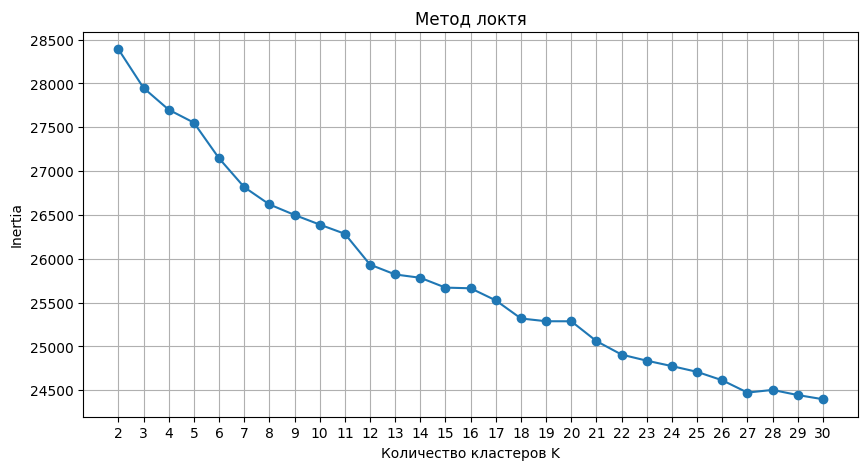

In [14]:
k_values = range(2, 31)
inertias = []

for k in k_values:
    km = KMeans(n_clusters=k, init="k-means++", n_init=3, random_state=42)
    km.fit(X)
    inertias.append(km.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(k_values, inertias, marker='o')
plt.xlabel('Количество кластеров K'); plt.ylabel('Inertia')
plt.title('Метод локтя'); plt.xticks(k_values); plt.grid(True)
plt.show()

Строим график зависимости inertia от выбранного К, ищем точку на графике ("локоть"), после которой дальнейшее увеличение (K) приводит только к небольшому уменьшению inertia.

Излом не выражен: inertia убывает плавно. Для TF-IDF это типично: данные высокоразмерные, и чётко отделённых сгустков в них нет.

Можно попробовать найти излом автоматически.

In [15]:
%pip install kneed -q


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip3.12 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [16]:
from kneed import KneeLocator

kl = KneeLocator(
    x=list(k_values),
    y=inertias,
    curve="convex",
    direction="decreasing",
    S=1.0
)

K_elbow = kl.knee
print("Точка излома: K =", K_elbow)

Точка излома: K = 12


KneeLocator реализует алгоритм Kneedle:

1. Оси K и inertia нормируются в [0, 1].

2. Строится разностная кривая: насколько нормированная кривая отклоняется от прямой, соединяющей её первую и последнюю точки.

3. Точка излома – K, где это отклонение максимально, то есть где кривая сильнее всего «прогибается».

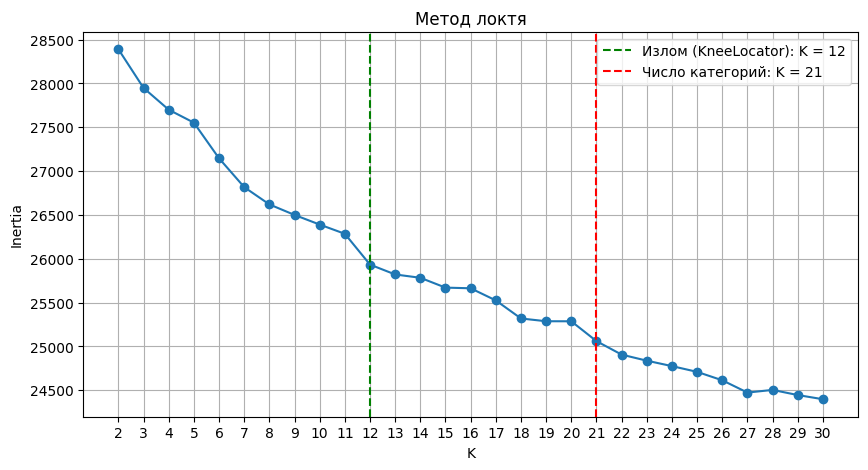

In [17]:
plt.figure(figsize=(10, 5))
plt.plot(k_values, inertias, marker='o')
plt.axvline(K_elbow, color='green', linestyle='--', label=f'Излом (KneeLocator): K = {K_elbow}')
plt.axvline(21, color='red', linestyle='--', label='Число категорий: K = 21')
plt.xlabel('K'); plt.ylabel('Inertia'); plt.title('Метод локтя')
plt.xticks(k_values); plt.grid(True); plt.legend()
plt.show()



---



In [18]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEEDS = [0, 1, 2, 3, 4] # добавим для задания нескольких начальных состояний и последующего усреднения, чтобы минимизировать влияние случайности

def make_models(K, seed):
    return {
        "K-Means":           KMeans(n_clusters=K, init="random",    n_init=10, random_state=seed),
        "K-Means++":         KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=seed),
        "MiniBatch K-Means": MiniBatchKMeans(n_clusters=K, init="k-means++", n_init=10,
                                             batch_size=2048, random_state=seed),
    }

rows = []
for seed in SEEDS:
    for name, model in make_models(K_elbow, seed).items():
        t0 = time.perf_counter()
        labels = model.fit_predict(X)
        t = time.perf_counter() - t0

        rows.append({
            "method":     name,
            "seed":       seed,
            "time_s":     t,
            "ARI":        adjusted_rand_score(y, labels),
            "silhouette": silhouette_score(X, labels, sample_size=10_000, random_state=42),
            "inertia":    model.inertia_,
            "n_iter":     model.n_iter_,
        })

runs = pd.DataFrame(rows)

summary = (runs.groupby("method")[["time_s", "ARI", "silhouette", "inertia", "n_iter"]]
               .agg(["mean", "std"])
               .round(4))
summary

time_s             ARI         silhouette          \
                     mean     std    mean     std       mean     std   
method                                                                 
K-Means            2.9895  0.3620  0.0170  0.0027     0.0330  0.0045   
K-Means++          3.9552  0.5873  0.0134  0.0027     0.0304  0.0051   
MiniBatch K-Means  0.3922  0.0149  0.0217  0.0063     0.0343  0.0046   

                      inertia           n_iter          
                         mean       std   mean     std  
method                                                  
K-Means            26011.1348   47.9554   27.4  5.4129  
K-Means++          25975.6538   35.7252   27.2  6.3008  
MiniBatch K-Means  26288.9104  120.4866    4.0  1.0000

Почему внутренняя оценка (silhouette) низкая:

- Большое количество признаков (чем больше размерность, тем больше расстояния между точками похожи друг на друга);

- В данных нет чётко разделённых сгустков. Тексты образуют сплошное облако с плавными переходами.

Почему внешняя оценка (ARI) низкая:

- Отзыв описывает впечатление от самого товара, а не его категорию, k-means скорее всего группирует отзывы по типу высказывания;

- K = 12 при 21 категории. Часть категорий неизбежно сливается, что дополнительно снижает ARI;

- Сильный дисбаланс классов. K-Means тяготеет к кластерам примерно одного размера, поэтому мелкие категории растворяются в крупных кластерах.

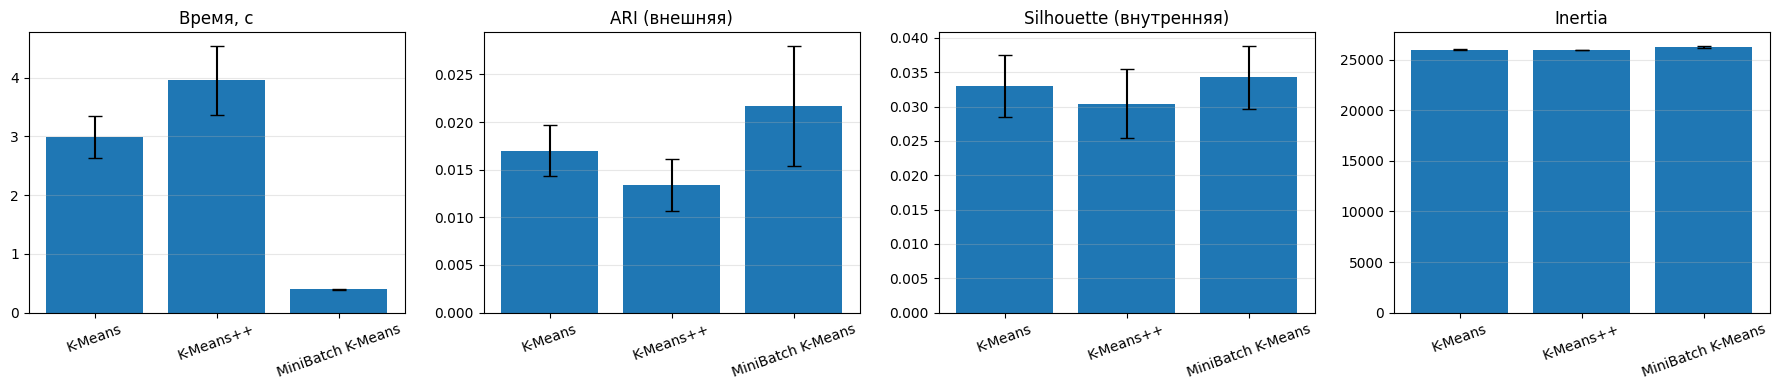

In [19]:
metrics = ["time_s", "ARI", "silhouette", "inertia"]
titles  = ["Время, с", "ARI (внешняя)", "Silhouette (внутренняя)", "Inertia"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, m, title in zip(axes, metrics, titles):
    stats = runs.groupby("method")[m].agg(["mean", "std"])
    ax.bar(stats.index, stats["mean"], yerr=stats["std"], capsize=5)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Плотностный метод

### DBSCAN — математическое описание

**DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) рассматривает кластер как область высокой плотности объектов.

Для каждой точки $p$ берётся её $\varepsilon$-окрестность $N_\varepsilon(p)=\{q:\rho(p,q)\le\varepsilon\}$. Точка **ядровая**, если $|N_\varepsilon(p)|\ge \text{min\_samples}$. Кластер — множество ядровых точек, связанных отношением плотностной достижимости, вместе с граничными точками их окрестностей; не попавшие ни в один кластер точки помечаются как **шум** (метка $-1$).

Параметры: $\varepsilon$ (радиус) и $\text{min\_samples}$ (порог плотности). $\varepsilon$ выбираем по графику расстояний до $k$-го соседа ($k=\text{min\_samples}$) — в точке излома. Число кластеров заранее не задаётся; метод находит кластеры произвольной формы и выделяет шум.

In [20]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

cluster_results = []

def evaluate(name, labels, t, Xm=None):
    Xm = X if Xm is None else Xm
    labels = np.asarray(labels)
    mask = labels != -1                      # для DBSCAN/HDBSCAN считаем silhouette без шума
    k = len(set(labels[mask].tolist()))
    ari = adjusted_rand_score(y, labels)     # ARI — по всем точкам
    if k > 1 and mask.sum() > k:
        sil = silhouette_score(Xm[mask], labels[mask],
                               sample_size=min(10_000, int(mask.sum())), random_state=42)
    else:
        sil = np.nan
    row = {"method": name, "n_clusters": k,
           "noise_%": round(float((labels == -1).mean()) * 100, 1),
           "ARI": round(ari, 4),
           "silhouette": (round(float(sil), 4) if sil == sil else None),
           "time_s": round(t, 2)}
    cluster_results.append(row); print(row)
    return row

### Подбор параметров DBSCAN

У DBSCAN два параметра: **`min_samples`** (сколько соседей в радиусе нужно, чтобы точка была ядровой — порог плотности) и **`eps`** (радиус окрестности). Подбираем их согласованно: сначала смотрим **график k-расстояний** (расстояние до `min_samples`-го соседа) для нескольких `min_samples`, затем делаем **полный перебор** `min_samples × eps` и оцениваем число кластеров, долю шума, silhouette и ARI.

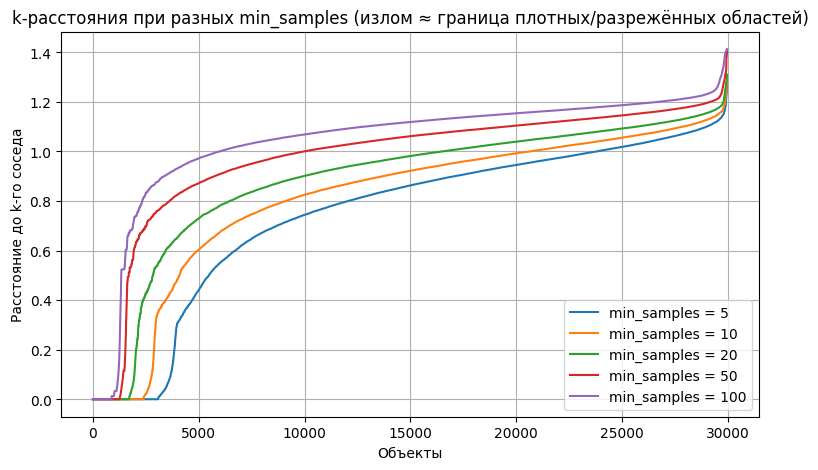

In [21]:
from sklearn.neighbors import NearestNeighbors

plt.figure(figsize=(9, 5))
for ms in [5, 10, 20, 50, 100]:
    d, _ = NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)
    plt.plot(np.sort(d[:, -1]), label=f"min_samples = {ms}")
plt.xlabel("Объекты")
plt.ylabel("Расстояние до k-го соседа")
plt.title("k-расстояния при разных min_samples (излом ≈ граница плотных/разрежённых областей)")
plt.legend(); plt.grid(True); plt.show()

На графике по оси X — объекты (отзывы), отсортированные по расстоянию до их min_samples-го соседа. У кривых два перегиба: первый — у нуля (первые ~2500 точек, расстояние ≈0) — это почти дословные дубли коротких отзывов; второй, рабочий «локоть» — на ≈0.4–0.5, граница плотных и разрежённых областей, его и берём за eps. Рост кривой после локтя плавный, без второго резкого скачка, что уже указывает на отсутствие выраженной плотностной структуры. Чем больше min_samples, тем выше кривая: больше требуемых соседей → их приходится искать дальше.

#### Полный перебор `min_samples × eps`
Для каждой пары считаем: число кластеров, долю шума, silhouette (по не-шумовым точкам) и ARI (по всем). Прогон на полном `X` (30k) — может занять 1–2 минуты.

In [22]:
from sklearn.cluster import DBSCAN
import time

ms_values  = [5, 10, 20, 50, 100]
eps_values = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

rows = []
for ms in ms_values:
    for eps in eps_values:
        t0 = time.perf_counter()
        lab = DBSCAN(eps=eps, min_samples=ms, metric="euclidean", n_jobs=-1).fit_predict(X)
        t = time.perf_counter() - t0
        m = lab != -1
        k = len(set(lab[m].tolist()))
        sil = (silhouette_score(X[m], lab[m], sample_size=min(5000, int(m.sum())), random_state=42)
               if k > 1 and m.sum() > k else np.nan)
        rows.append({"min_samples": ms, "eps": eps, "n_clusters": k,
                     "noise_%": round(float((lab == -1).mean()) * 100, 1),
                     "silhouette": round(float(sil), 3) if sil == sil else np.nan,
                     "ARI": round(adjusted_rand_score(y, lab), 4), "time_s": round(t, 1)})

dbscan_grid = pd.DataFrame(rows)
dbscan_grid

,min_samples,eps,n_clusters,noise_%,silhouette,ARI,time_s
0,5,0.3,255,86.7,0.955,-0.0018,3.6
1,5,0.4,316,83.7,0.804,-0.0021,3.6
2,5,0.5,338,80.2,0.596,-0.0020,3.7
3,5,0.6,371,74.2,0.383,-0.0022,3.9
4,5,0.7,321,63.9,0.067,0.0008,4.0
5,5,0.8,147,48.2,-0.072,0.0076,4.1
6,10,0.3,91,90.1,0.960,-0.0013,4.3
7,10,0.4,119,88.0,0.836,-0.0014,4.4
8,10,0.5,137,84.9,0.627,-0.0020,4.3
9,10,0.6,155,80.3,0.437,-0.0023,4.5


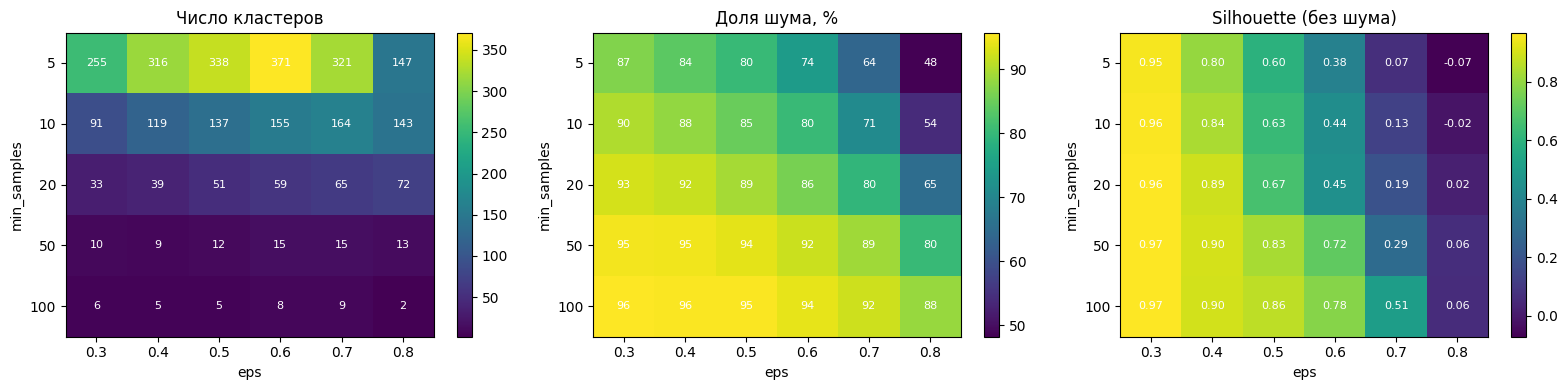

In [23]:
# визуализация перебора: тепловые карты по сетке min_samples × eps
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, ["n_clusters", "noise_%", "silhouette"],
                          ["Число кластеров", "Доля шума, %", "Silhouette (без шума)"]):
    piv = dbscan_grid.pivot(index="min_samples", columns="eps", values=col)
    im = ax.imshow(piv.values, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels(piv.columns)
    ax.set_yticks(range(len(piv.index)));   ax.set_yticklabels(piv.index)
    ax.set_xlabel("eps"); ax.set_ylabel("min_samples"); ax.set_title(title)
    for (r, c), v in np.ndenumerate(piv.values):
        if v == v:
            ax.text(c, r, f"{v:.2f}" if col == "silhouette" else f"{v:.0f}",
                    ha="center", va="center", color="white", fontsize=8)
    plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

> Перебор `min_samples × eps` (30 комбинаций) не выявил устойчивой кластеризации:
>
> - **silhouette и доля шума меняются синхронно** — высокие значения silhouette (0.95–0.97) достигаются только при доле шума 80–96 %. Это значит, что в кластеры попадают лишь плотные ядра (дубли), а 80–95 % объектов отбрасываются в шум; такая silhouette несопоставима с методами без шума и завышена.
> - при снижении шума (большой `eps`, напр. 0.8) кластеры сливаются, и silhouette падает до ≈0 и ниже.
> - **ARI ≈ 0 при любых параметрах** (−0.002…+0.008) — разбиение не совпадает с категориями ни в одной конфигурации.
> - по строкам (рост `min_samples` с 5 до 100) число кластеров падает (255 → 6), а шум растёт (87 → 96 %) — большой порог плотности толкает к «одному кому / сплошному шуму».
>
> «Рабочей зоны» (много кластеров + низкий шум + высокая silhouette) нет — это и есть вывод: в 700-мерных TF-IDF/LSA-векторах отзывов плотностно разделённых кластеров по категориям не существует.

In [24]:
# Итоговый DBSCAN: показываем компромисс между silhouette и долей шума.
# «Хорошей» пары параметров нет, поэтому фиксируем две граничные точки.
import time

configs = {
    "DBSCAN (высокая silhouette)": dict(eps=0.5, min_samples=10),  
    "DBSCAN (низкий шум)":         dict(eps=0.8, min_samples=5),   
}

for name, prm in configs.items():
    t0 = time.perf_counter()
    lab = DBSCAN(metric="euclidean", n_jobs=-1, **prm).fit_predict(X)
    t = time.perf_counter() - t0
    print(f"{name}: eps={prm['eps']}, min_samples={prm['min_samples']}")
    evaluate(name, lab, t)

# основной вариант для дальнейших визуализаций и сравнения
EPS, min_samples = 0.5, 10
labels_db = DBSCAN(eps=EPS, min_samples=min_samples, metric="euclidean", n_jobs=-1).fit_predict(X)

DBSCAN (высокая silhouette): eps=0.5, min_samples=10
{'method': 'DBSCAN (высокая silhouette)', 'n_clusters': 137, 'noise_%': 84.9, 'ARI': -0.002, 'silhouette': 0.6268, 'time_s': 4.53}
DBSCAN (низкий шум): eps=0.8, min_samples=5
{'method': 'DBSCAN (низкий шум)', 'n_clusters': 147, 'noise_%': 48.2, 'ARI': 0.0076, 'silhouette': -0.0463, 'time_s': 4.46}


Две граничные конфигурации наглядно показывают компромисс DBSCAN. При eps=0.5 silhouette высокая (0.63), но лишь потому, что 84.9 % объектов отброшены в шум, а в кластеры попали в основном дубли. При eps=0.8 шум падает до 48.2 %, но silhouette сразу уходит в минус (−0.05) — кластеры перестают быть плотными. В обоих случаях ARI ≈ 0: с категориями разбиение не совпадает. Таким образом, одновременно получить и низкий шум, и высокую silhouette не удаётся — устойчивой плотностной структуры в данных нет.

### Эксперимент: влияние размерности на DBSCAN

Высокая размерность мешает плотностным методам. Повторим DBSCAN на первых **150** компонентах SVD (топ по сингулярным значениям) с повторной L2-нормировкой и сравним долю шума и число кластеров с версией на 700 измерениях.

In [25]:
from sklearn.preprocessing import normalize

X150 = normalize(X[:, :150])

# тот же перебор параметров, что и на 700D
rows150 = []
for ms in ms_values:
    for eps in eps_values:
        t0 = time.perf_counter()
        lab = DBSCAN(eps=eps, min_samples=ms, metric="euclidean", n_jobs=-1).fit_predict(X150)
        t = time.perf_counter() - t0
        m = lab != -1
        k = len(set(lab[m].tolist()))
        sil = (silhouette_score(X150[m], lab[m], sample_size=min(5000, int(m.sum())), random_state=42)
               if k > 1 and m.sum() > k else np.nan)
        rows150.append({"min_samples": ms, "eps": eps, "n_clusters": k,
                        "noise_%": round(float((lab == -1).mean()) * 100, 1),
                        "silhouette": round(float(sil), 3) if sil == sil else np.nan,
                        "ARI": round(adjusted_rand_score(y, lab), 4), "time_s": round(t, 1)})

dbscan_grid150 = pd.DataFrame(rows150)
dbscan_grid150

,min_samples,eps,n_clusters,noise_%,silhouette,ARI,time_s
0,5,0.3,470,73.5,0.788,-0.0023,1.1
1,5,0.4,491,67.1,0.599,-0.0026,1.1
2,5,0.5,406,58.3,0.281,-0.0011,1.0
3,5,0.6,203,44.6,-0.047,0.0012,1.1
4,5,0.7,25,25.0,-0.067,0.0021,1.1
5,5,0.8,5,8.3,-0.022,0.0009,1.1
6,10,0.3,182,79.6,0.840,-0.0020,1.0
7,10,0.4,219,74.0,0.676,-0.0031,1.1
8,10,0.5,211,64.7,0.384,-0.0019,1.1
9,10,0.6,145,50.5,0.086,-0.0002,1.0


На 150 компонентах DBSCAN ведёт себя менее вырожденно, чем на 700: при тех же параметрах доля шума заметно ниже (например, при ms=10, eps=0.5 — 64.7 % против 84.9 %), появляется промежуточный режим с умеренным шумом (25 % при ms=5, eps=0.7), расчёт быстрее. Это подтверждает, что высокая размерность разрежала окрестности. Однако качественно результат тот же: ARI ≈ 0 при любых параметрах, а высокая silhouette по-прежнему достигается только ценой большого шума. Снижение размерности смягчает проблему, но не создаёт кластерную структуру по категориям — её в текстах отзывов нет.

## Иерархический метод

### Агломеративная кластеризация (Уорда) — математическое описание

**Агломеративный** метод работает снизу вверх: сначала каждый объект — отдельный кластер, затем на каждом шаге объединяются два ближайших кластера, пока не останется заданное число $K$. Последовательность вложенных разбиений изображается **дендрограммой**.

Близость кластеров — **критерий Уорда**: объединяются $A$ и $B$ с минимальным приростом внутрикластерной суммы квадратов
$$\Delta(A,B)=\frac{|A|\,|B|}{|A|+|B|}\,\lVert \mu_A-\mu_B\rVert^2,$$
где $\mu_A,\mu_B$ — центроиды кластеров. Для выполнимости на 30 000 объектов используем граф $k$ ближайших соседей (`connectivity`), который ограничивает возможные слияния соседними точками.

**Обоснование выбора linkage.** Сравним четыре стратегии связывания на подвыборке (3 000) по трём критериям: **кофенетическая корреляция** (насколько дендрограмма сохраняет исходные расстояния, ближе к 1 — лучше), **silhouette** и **ARI** при $K$ кластерах. Выбираем linkage с лучшим сочетанием; `ward` ожидаемо даёт компактные кластеры, `single` — склонен к «цепочке».

In [26]:
from scipy.cluster.hierarchy import linkage, cophenet, fcluster
from scipy.spatial.distance import pdist

rng = np.random.default_rng(42)
sub_idx = rng.choice(len(X), 3_000, replace=False)
Xs, ys = X[sub_idx], y[sub_idx]
D = pdist(Xs)                       # попарные евклидовы расстояния
Kc = int(K_elbow)

rows = []
for m in ["single", "complete", "average", "ward"]:
    Z = linkage(Xs, method=m)
    coph, _ = cophenet(Z, D)
    lab = fcluster(Z, t=Kc, criterion="maxclust")
    sil = silhouette_score(Xs, lab) if len(set(lab)) > 1 else np.nan
    ari = adjusted_rand_score(ys, lab)
    rows.append({"linkage": m, "cophenetic": round(coph, 3),
                 "silhouette": round(float(sil), 4), "ARI": round(ari, 4),
                 "n_clusters": len(set(lab))})
pd.DataFrame(rows).set_index("linkage")

,cophenetic,silhouette,ARI,n_clusters
linkage,,,,
single,0.207,-0.0046,-0.0002,12
complete,0.358,-0.0192,0.0139,12
average,0.625,-0.0006,-0.0004,12
ward,-0.014,-0.0276,0.0064,12


По **кофенетической корреляции** лучший результат у **average** (0.625) — эта связь точнее сохраняет исходные попарные расстояния; у **ward** корреляция близка к нулю, так как ward оптимизирует внутрикластерную дисперсию, а не сохранение расстояний. При этом silhouette и ARI у всех linkage ≈ 0 — выраженной структуры в данных нет. Для итоговой кластеризации берём **ward** как стандартный иерархический метод (разобран в лекции), работающий с евклидовой метрикой (= косинус за счёт нормировки) и сопоставимый по подходу с K-Means. Как будет видно ниже, на этих данных ward всё же сводит большинство объектов в один кластер — отдельной структуры по категориям нет.

In [27]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.neighbors import kneighbors_graph

K = int(K_elbow)
conn = kneighbors_graph(X, n_neighbors=20, include_self=False)   # граф соседей для ward

# ward — основной иерархический метод, на всей выборке (евклид = косинус за счёт нормировки)
t0 = time.perf_counter()
labels_ward = AgglomerativeClustering(n_clusters=K, linkage="ward",
                                       connectivity=conn).fit_predict(X)
t_ward = time.perf_counter() - t0
evaluate("Agglomerative (ward)", labels_ward, t_ward)

{'method': 'Agglomerative (ward)', 'n_clusters': 12, 'noise_%': 0.0, 'ARI': 0.0014, 'silhouette': -0.0368, 'time_s': 5.65}


{'method': 'Agglomerative (ward)',
 'n_clusters': 12,
 'noise_%': 0.0,
 'ARI': 0.0014,
 'silhouette': -0.0368,
 'time_s': 5.65}

**Ward (полная выборка, $K=12$):** разбиение построено за ~5 с, без шума (0 %), все объекты распределены по 12 кластерам. Качество низкое: ARI = 0.0014 (на уровне случайного), silhouette = −0.037 (слегка отрицательна — в среднем точки чуть ближе к соседним кластерам, чем к своему, то есть кластеры не разделены). Ниже посмотрим на распределение размеров кластеров.

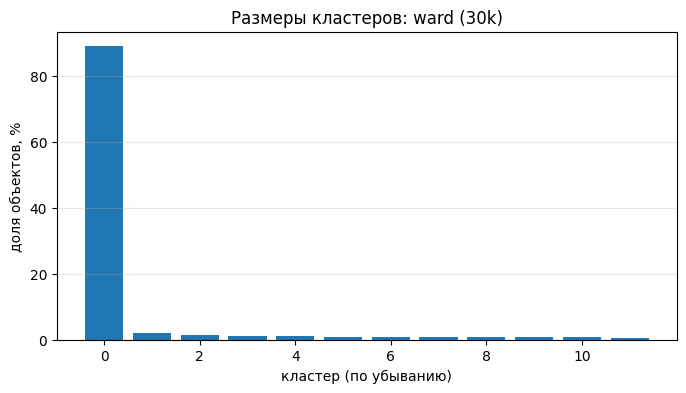

крупнейший кластер = 89.0%, кластеров с <1% объектов = 7


In [28]:
_, cnts = np.unique(labels_ward, return_counts=True)
shares = np.sort(cnts)[::-1] / cnts.sum() * 100

plt.figure(figsize=(8, 4))
plt.bar(range(len(shares)), shares)
plt.title("Размеры кластеров: ward (30k)")
plt.xlabel("кластер (по убыванию)"); plt.ylabel("доля объектов, %")
plt.grid(axis="y", alpha=0.3)
plt.show()

print(f"крупнейший кластер = {cnts.max()/cnts.sum():.1%}, "
      f"кластеров с <1% объектов = {int((cnts < 0.01*cnts.sum()).sum())}")

Разбиение ward сильно несбалансировано: один кластер вбирает 89 % объектов, 7 из 12 кластеров содержат менее 1 %. Фактически метод выделил одну доминирующую массу и несколько периферийных «обрывков», а не 12 содержательных групп. Это объясняет слегка отрицательную silhouette (почти все точки в одном кластере — разделённости нет) и ARI ≈ 0. Результат согласуется с DBSCAN («один блоб / шум») и подтверждает: в данных нет выраженной кластерной структуры — любой метод сводит отзывы либо к одной большой группе, либо к шуму.

In [29]:
from sklearn.cluster import Birch

# BIRCH — второй иерархический метод (масштабируемое дерево признаков)
t0 = time.perf_counter()
labels_birch = Birch(n_clusters=K).fit_predict(X)
t_birch = time.perf_counter() - t0
evaluate("BIRCH", labels_birch, t_birch)

{'method': 'BIRCH', 'n_clusters': 12, 'noise_%': 0.0, 'ARI': 0.0336, 'silhouette': 0.0026, 'time_s': 49.0}


{'method': 'BIRCH',
 'n_clusters': 12,
 'noise_%': 0.0,
 'ARI': 0.0336,
 'silhouette': 0.0026,
 'time_s': 49.0}

BIRCH (K=12): без шума (0 %), все объекты распределены по 12 кластерам за ~49 с. ARI = 0.034 — наивысший среди всех методов, но в абсолютном выражении это по-прежнему близко к нулю (совпадение с категориями почти случайное). silhouette = 0.003 — кластеры практически не разделены. BIRCH строит иерархическое дерево признаков (CF-tree) и масштабируется на большие выборки, но здесь его преимущество по ARI незначимо, а считается он заметно дольше ward (~49 с против ~5 с).

# Сравнение качества и скорости кластеризаторов

In [30]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

**Выбор метрик.** Внешняя — **ARI (Adjusted Rand Index)**: есть истинные метки (категории), ARI измеряет согласованность разбиений с поправкой на случайность, не зависит от перестановки меток и работает при разном числе кластеров. Внутренняя — **silhouette**: не требует меток, оценивает компактность и отделённость кластеров.

Оговорки по адекватности silhouette:
- для DBSCAN silhouette считается **только по не-шумовым точкам**, поэтому при доле шума 80–95 % она измеряет качество лишь на малой части данных и **несопоставима** с методами без шума — её высокие значения (0.6–0.95) не означают лучшую кластеризацию;
- silhouette предполагает выпуклые кластеры, что дополнительно занижает её для плотностных методов.

Поэтому метрики интерпретируются **вместе с долей шума** (`noise_%`): сравнивать silhouette имеет смысл только между методами с сопоставимым покрытием (0 % шума: K-Means, K-Means++, MiniBatch, BIRCH, Agglomerative).

In [31]:
# единый прогон центроидных методов
for name, model in {
    "K-Means":           KMeans(n_clusters=int(K_elbow), init="random",    n_init=10, random_state=42),
    "K-Means++":         KMeans(n_clusters=int(K_elbow), init="k-means++", n_init=10, random_state=42),
    "MiniBatch K-Means": MiniBatchKMeans(n_clusters=int(K_elbow), init="k-means++", n_init=10,
                                         batch_size=2048, random_state=42),
}.items():
    t0 = time.perf_counter(); lab = model.fit_predict(X); t = time.perf_counter() - t0
    evaluate(name, lab, t)

# итоговая таблица (на случай повторных запусков оставляем последнюю запись каждого метода)
comparison = (pd.DataFrame(cluster_results)
                .drop_duplicates("method", keep="last")
                .set_index("method"))
comparison

{'method': 'K-Means', 'n_clusters': 12, 'noise_%': 0.0, 'ARI': 0.0195, 'silhouette': 0.0348, 'time_s': 3.1}
{'method': 'K-Means++', 'n_clusters': 12, 'noise_%': 0.0, 'ARI': 0.0137, 'silhouette': 0.0248, 'time_s': 4.97}
{'method': 'MiniBatch K-Means', 'n_clusters': 12, 'noise_%': 0.0, 'ARI': 0.0312, 'silhouette': 0.0376, 'time_s': 0.51}


,n_clusters,noise_%,ARI,silhouette,time_s
method,,,,,
DBSCAN (высокая silhouette),137,84.9,-0.0020,0.6268,4.53
DBSCAN (низкий шум),147,48.2,0.0076,-0.0463,4.46
Agglomerative (ward),12,0.0,0.0014,-0.0368,5.65
BIRCH,12,0.0,0.0336,0.0026,49.00
K-Means,12,0.0,0.0195,0.0348,3.10
K-Means++,12,0.0,0.0137,0.0248,4.97
MiniBatch K-Means,12,0.0,0.0312,0.0376,0.51


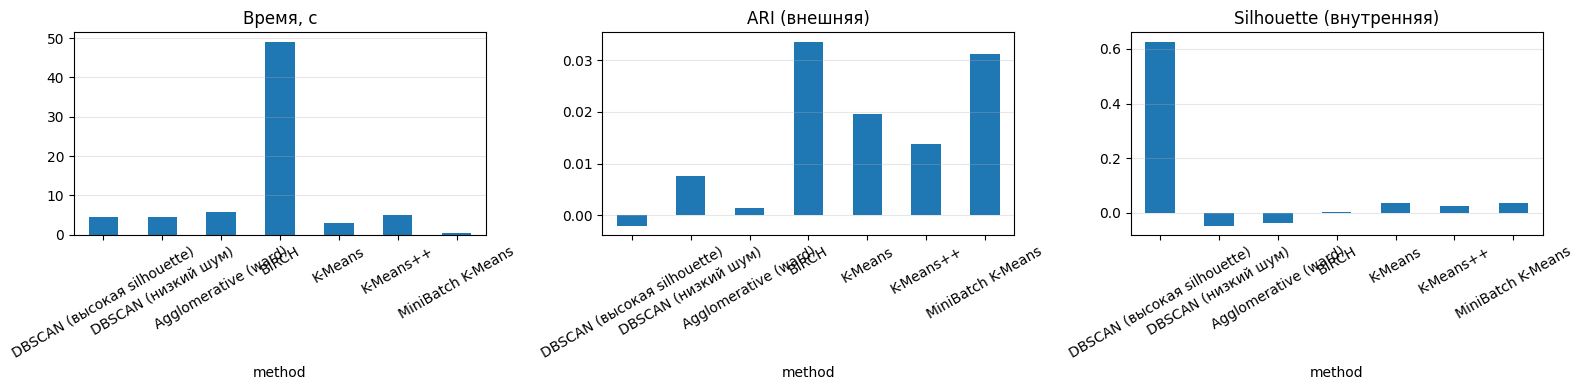

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, m, title in zip(axes, ["time_s", "ARI", "silhouette"],
                        ["Время, с", "ARI (внешняя)", "Silhouette (внутренняя)"]):
    comparison[m].plot(kind="bar", ax=ax)
    ax.set_title(title); ax.tick_params(axis="x", rotation=30); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

# Выводы

По результатам кластеризации можно сделать следующие выводы.

- **Внешнее качество (ARI) у всех методов близко к нулю** (лучшие — BIRCH 0.034 и MiniBatch 0.031). Отзывы группируются по лексике и манере высказывания, а не по категориям товаров; мешают также дисбаланс классов и несовпадение числа кластеров ($K=12$) с числом категорий (21).
- **Внутреннее качество (silhouette) низкое** у всех методов с полным покрытием (K-Means ≈ 0.03, BIRCH ≈ 0.00, ward < 0): в 700-мерном пространстве TF-IDF/LSA нет чётко разделённых сгустков. Высокая silhouette у DBSCAN при малом `eps` (до 0.95) — артефакт: она посчитана по не-шумовым точкам (всего 5–20 % данных, в основном дубли) и несопоставима с остальными.
- **Центроидные методы** (K-Means, K-Means++, MiniBatch) по качеству близки; **MiniBatch** — лучший компромисс: ARI 0.031 при ~0.45 c (в разы быстрее остальных).
- **Плотностный DBSCAN** не нашёл полезной структуры: при большом `eps` всё сливается в один кластер, при малом — 80–95 % объектов уходит в шум, а выделяются лишь дубли; ARI ≈ 0 при любых параметрах. Снижение размерности до 150 компонент картину не изменило — проблема не в размерности, а в отсутствии тематической структуры.
- **Иерархические методы** (Ward, BIRCH) распределяют все объекты без шума на 12 кластеров, но ward сводит ~89 % объектов в один доминирующий кластер (остальные — мелкие «обрывки»); BIRCH даёт наибольший ARI (0.034), но самый медленный (≈49 c).
- **Итог:** ни один метод не восстанавливает категории товаров — кластеры отражают стиль отзывов, а не тему. Для повышения ARI нужны признаки ближе к теме товара (например, по названию/составу) и/или работа с дисбалансом классов. По совокупности «качество/скорость» для данной задачи предпочтителен **MiniBatch K-Means**.